# 01 - Exploración de los datos

Objetivo: entender qué contiene el dataset antes de modelar. Cada fila es una estrella y cada columna un instante de medición del flujo luminoso (curva de luz).

In [1]:
import sys
sys.path.append('..')

import numpy as np
import matplotlib.pyplot as plt
from src.data import load_train_test

X_train, y_train, X_test, y_test = load_train_test()
print('train:', X_train.shape, '| test:', X_test.shape)

train: (5087, 3197) | test: (570, 3197)


## 1. Desbalance de clases

Cuántas estrellas tienen exoplaneta (1) y cuántas no (0).

train: 5087 estrellas, 37 con planeta (0.73%)
   accuracy de un clasificador que siempre dice "sin planeta": 99.27%
test: 570 estrellas, 5 con planeta (0.88%)
   accuracy de un clasificador que siempre dice "sin planeta": 99.12%


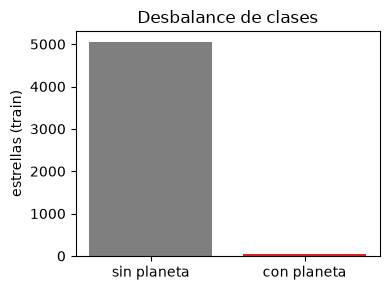

In [2]:
for nombre, y in [('train', y_train), ('test', y_test)]:
    pos = y.sum()
    print(f'{nombre}: {len(y)} estrellas, {pos} con planeta ({100*pos/len(y):.2f}%)')
    print(f'   accuracy de un clasificador que siempre dice "sin planeta": {100*(1-pos/len(y)):.2f}%')

fig, ax = plt.subplots(figsize=(4, 3))
ax.bar(['sin planeta', 'con planeta'], [(y_train == 0).sum(), (y_train == 1).sum()], color=['tab:gray', 'tab:red'])
ax.set_ylabel('estrellas (train)')
ax.set_title('Desbalance de clases')
plt.tight_layout()
plt.savefig('../results/01_desbalance.png', dpi=150)
plt.show()

**Observación:** solo ~0,7% de las estrellas tiene planeta. Un modelo que diga siempre "sin planeta" logra ~99% de accuracy sin detectar nada. Por eso usaremos recall, precisión, F1 y PR-AUC.

## 2. Curvas de luz de ejemplo

Cuatro estrellas con planeta (arriba) y cuatro sin planeta (abajo), en crudo.

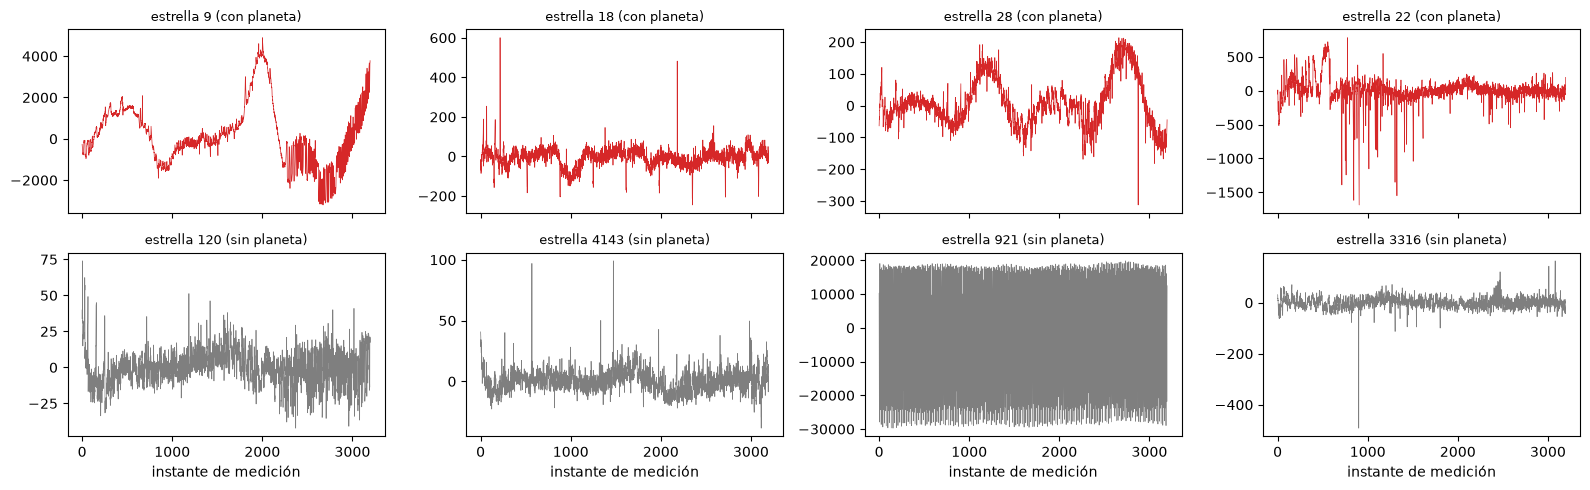

In [3]:
rng = np.random.default_rng(0)
con = rng.choice(np.where(y_train == 1)[0], 4, replace=False)
sin = rng.choice(np.where(y_train == 0)[0], 4, replace=False)

fig, axes = plt.subplots(2, 4, figsize=(16, 5), sharex=True)
for fila, (idx, titulo, color) in enumerate([(con, 'con planeta', 'tab:red'), (sin, 'sin planeta', 'tab:gray')]):
    for col, i in enumerate(idx):
        axes[fila, col].plot(X_train[i], lw=0.5, color=color)
        axes[fila, col].set_title(f'estrella {i} ({titulo})', fontsize=9)
for ax in axes[1]:
    ax.set_xlabel('instante de medición')
plt.tight_layout()
plt.savefig('../results/01_curvas_ejemplo.png', dpi=150)
plt.show()

**Observación:** las curvas crudas tienen tendencias lentas y escalas muy distintas entre estrellas; el tránsito de un planeta (una caída pequeña y breve) no se ve a simple vista. Esto justifica el *detrending* y la normalización del Paso 4.

## 3. Escala del flujo y valores faltantes

NaN en train: 0 | NaN en test: 0
Desviación estándar por estrella: min=1.7, mediana=40.1, max=1053242.7


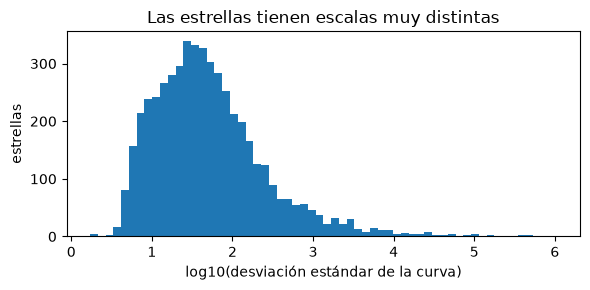

In [4]:
print('NaN en train:', np.isnan(X_train).sum(), '| NaN en test:', np.isnan(X_test).sum())
desv = X_train.std(axis=1)
print('Desviación estándar por estrella: min={:.1f}, mediana={:.1f}, max={:.1f}'.format(desv.min(), np.median(desv), desv.max()))

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(np.log10(desv + 1e-9), bins=60)
ax.set_xlabel('log10(desviación estándar de la curva)')
ax.set_ylabel('estrellas')
ax.set_title('Las estrellas tienen escalas muy distintas')
plt.tight_layout()
plt.savefig('../results/01_escalas.png', dpi=150)
plt.show()

**Observación:** no hay valores faltantes, pero las escalas varían en varios órdenes de magnitud entre estrellas. Normalizar cada curva es obligatorio para comparar estrellas entre sí.